<div dir="rtl">

# تمرين 4.3: تقرير الصفحة الواحدة

**برنامج التجارب واختبارات A/B والاستدلال السببي**، اليوم الرابع

**الخطوات:**
1. من قائمة File اختر Save a copy in Drive، واعمل على النسخة التي تُفتح.
2. شغّل الخلايا بالترتيب، ثم اكتب حلك في الخلية المخصصة.
3. اضغط Share، واجعل General access على Anyone with the link بصلاحية Viewer، ثم اضغط Copy link.
4. الصق الرابط في ملف التقييم الخاص بمجموعتك، في عمود «تمرين 4.3».

</div>

<div dir="rtl">

## الإعداد

شغّل الخلية التالية أولًا.

</div>

In [1]:
import warnings
warnings.filterwarnings("ignore")

import html
from IPython.display import HTML, display

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from cycler import cycler
from matplotlib import ft2font
from scipy import stats

# الإصدارات الحديثة من matplotlib تعرض العربية مباشرة، والقديمة تحتاج مكتبتين صغيرتين
NATIVE_ARABIC = hasattr(ft2font, "__libraqm_version__")
if not NATIVE_ARABIC:
    try:
        import arabic_reshaper
        from bidi.algorithm import get_display
    except ImportError:
        import subprocess
        import sys
        subprocess.run([sys.executable, "-m", "pip", "install", "-q", "arabic-reshaper", "python-bidi"], check=True)
        import arabic_reshaper
        from bidi.algorithm import get_display

rng = np.random.default_rng(2026)

# ألوان البرنامج: A تركوازي، وB برتقالي، والقيمة الحقيقية كحلي، والطريقة الساذجة رمادي
TEAL, ORANGE, NAVY, GRAY = "#0E7490", "#E58A1F", "#0F2A3F", "#A9B4BC"
plt.rcParams.update({
    "figure.figsize": (9, 4.5), "figure.dpi": 110,
    "axes.prop_cycle": cycler(color=[TEAL, ORANGE, NAVY, GRAY]),
    "axes.edgecolor": "#56656F", "axes.labelcolor": NAVY, "text.color": NAVY,
    "xtick.color": "#3D4F5C", "ytick.color": "#3D4F5C",
    "axes.grid": True, "grid.color": "#D8E1E7", "grid.linewidth": 0.8,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.titlesize": 13, "axes.titleweight": "bold", "font.size": 11,
    "legend.frameon": False,
})
pd.set_option("display.precision", 4)


def ar(text):
    """يجهز النص العربي ليظهر بالشكل والاتجاه الصحيحين داخل الرسوم."""
    text = str(text)
    return text if NATIVE_ARABIC else get_display(arabic_reshaper.reshape(text))


def say(*parts, sep=" "):
    """يطبع نصًا عربيًا من اليمين إلى اليسار."""
    text = html.escape(sep.join(str(p) for p in parts))
    display(HTML(f'<div dir="rtl" style="white-space: pre-wrap; line-height: 1.7;">{text}</div>'))


import networkx as nx
import statsmodels.formula.api as smf
from IPython.display import Markdown, display


def tidy(fit, terms=None):
    """جدول مختصر لنتيجة الانحدار."""
    ci = fit.conf_int()
    out = pd.DataFrame({"المعامل": fit.params, "SE": fit.bse, "أدنى 95%": ci[0], "أعلى 95%": ci[1], "p": fit.pvalues})
    return out.loc[terms] if terms else out


def draw_dag(ax, edges, pos, title, highlight=None, unobserved=()):
    """يرسم رسمًا سببيًا: البرتقالي هو المتغير المهم في المثال، والرمادي متغير لا نقيسه."""
    g = nx.DiGraph(edges)
    colors = ["#FCEBD7" if v == highlight else ("#E4E9ED" if v in unobserved else "#E0F0F4") for v in g.nodes]
    nx.draw_networkx(g, pos=pos, ax=ax, labels={v: ar(v) for v in g.nodes}, node_color=colors, node_size=4600,
                     font_size=9, font_color=NAVY, edgecolors=NAVY, edge_color=NAVY, arrowsize=16, width=1.2)
    ax.set_title(ar(title), fontsize=10.5)
    ax.axis("off")
    ax.margins(0.25)


say("الإعداد جاهز")

<div dir="rtl">

## الأدوات الجاهزة

هذه الدوال والبيانات من دفتر اليوم، ويحتاجها التمرين. شغّلها كما هي.

</div>

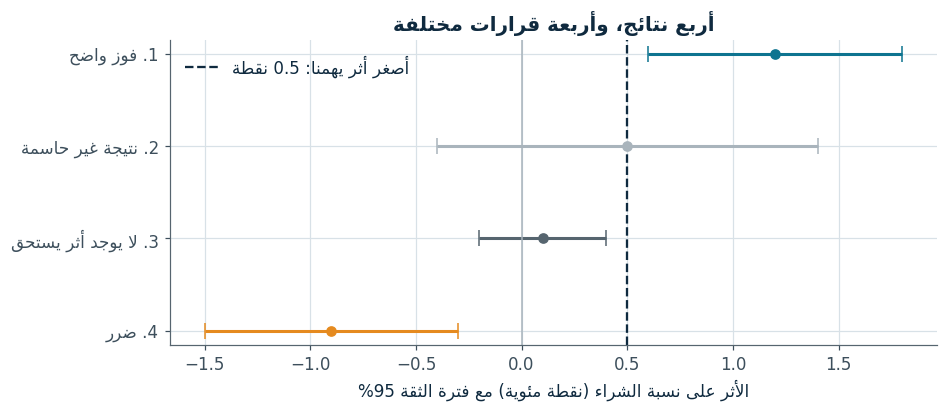

In [2]:
scenarios = [("1. فوز واضح", 1.2, 0.6, 1.8, TEAL), ("2. نتيجة غير حاسمة", 0.5, -0.4, 1.4, GRAY),
             ("3. لا يوجد أثر يستحق", 0.1, -0.2, 0.4, "#56656F"), ("4. ضرر", -0.9, -1.5, -0.3, ORANGE)]
mde = 0.5
fig, ax = plt.subplots(figsize=(9, 3.6))
for i, (label, est, lo, hi, color) in enumerate(scenarios):
    ax.errorbar(est, i, xerr=[[est - lo], [hi - est]], fmt="o", capsize=5, color=color, linewidth=2)
ax.set_yticks(range(len(scenarios)))
ax.set_yticklabels([ar(s[0]) for s in scenarios])
ax.axvline(0, color=GRAY, linewidth=1)
ax.axvline(mde, color=NAVY, linestyle="--", label=ar(f"أصغر أثر يهمنا: {mde} نقطة"))
ax.invert_yaxis()
ax.set_xlabel(ar("الأثر على نسبة الشراء (نقطة مئوية) مع فترة الثقة 95%"))
ax.set_title(ar("أربع نتائج، وأربعة قرارات مختلفة"))
ax.legend()
plt.show()

In [3]:
def decide(ci_low, ci_high, mde, guardrails_ok=True):
    if ci_high < 0:
        return "لا نطلق، لأن النسخة الجديدة أضرت بالمقياس الرئيسي."
    if ci_low > 0 and not guardrails_ok:
        return "لا نطلق الآن، لأن المقياس الرئيسي تحسن لكن أحد مقاييس الحماية ساء. نعالج المشكلة ثم نعيد التحقق."
    if ci_low > 0:
        return "نطلق، لأن الأثر إيجابي بثقة ومقاييس الحماية سليمة."
    if ci_high < mde:
        return "لا نطلق، لأننا استبعدنا وجود أثر بالحجم الذي يهمنا."
    return "لا نقرر بعد. نمدد التجربة، أو نعيد تصميمها بقوة أعلى."


for label, est, lo, hi, _ in scenarios:
    print(f"{label}: {decide(lo / 100, hi / 100, mde / 100)}")

1. فوز واضح: نطلق، لأن الأثر إيجابي بثقة ومقاييس الحماية سليمة.
2. نتيجة غير حاسمة: لا نقرر بعد. نمدد التجربة، أو نعيد تصميمها بقوة أعلى.
3. لا يوجد أثر يستحق: لا نطلق، لأننا استبعدنا وجود أثر بالحجم الذي يهمنا.
4. ضرر: لا نطلق، لأن النسخة الجديدة أضرت بالمقياس الرئيسي.


In [4]:
def one_page_report(title, effect, ci_low, ci_high, baseline, mde, guardrails, annual_visitors, avg_order_value,
                    caveats):
    """يحول نتيجة التجربة إلى تقرير من صفحة واحدة بلغة يفهمها من يتخذ القرار.
    اكتب حالة كل مقياس حماية لم يسؤ بكلمة "سليم"، واكتب وصفًا للمشكلة إذا ساء."""
    value = lambda x: x * annual_visitors * avg_order_value / 1e6
    guard_rows = "\n".join(f"| {name} | {status} |" for name, status in guardrails.items())
    guardrails_ok = all(status.strip().startswith("سليم") for status in guardrails.values())
    return f"""
<div dir="rtl">

### {title}

**القرار:** {decide(ci_low, ci_high, mde, guardrails_ok)}

| البند | القيمة |
|---|---|
| المقياس الرئيسي | نسبة الشراء: من {baseline:.1%} إلى {baseline + effect:.1%} |
| الأثر | {effect * 100:.2f} نقطة (فترة الثقة 95%: من {ci_low * 100:.2f} إلى {ci_high * 100:.2f}) |
| القيمة السنوية التقديرية | حوالي {value(effect):.1f} مليون ريال (من {value(ci_low):.1f} إلى {value(ci_high):.1f}) |

| مقياس الحماية | الحالة |
|---|---|
{guard_rows}

**القيود:** {caveats}

</div>
"""


display(Markdown(one_page_report(
    title="تجربة صفحة الدفع بخطوة واحدة",
    effect=0.0079, ci_low=0.0030, ci_high=0.0128, baseline=0.1013, mde=0.005,
    guardrails={"زمن تحميل الصفحة": "ساء بنسبة 7%", "أخطاء الدفع": "سليم", "الاسترجاع": "سليم"},
    annual_visitors=1_200_000, avg_order_value=250,
    caveats="مدة التجربة 3 أسابيع، والقيمة السنوية تفترض أن الأثر وعدد الزيارات سيبقيان كما هما.")))


<div dir="rtl">

### تجربة صفحة الدفع بخطوة واحدة

**القرار:** لا نطلق الآن، لأن المقياس الرئيسي تحسن لكن أحد مقاييس الحماية ساء. نعالج المشكلة ثم نعيد التحقق.

| البند | القيمة |
|---|---|
| المقياس الرئيسي | نسبة الشراء: من 10.1% إلى 10.9% |
| الأثر | 0.79 نقطة (فترة الثقة 95%: من 0.30 إلى 1.28) |
| القيمة السنوية التقديرية | حوالي 2.4 مليون ريال (من 0.9 إلى 3.8) |

| مقياس الحماية | الحالة |
|---|---|
| زمن تحميل الصفحة | ساء بنسبة 7% |
| أخطاء الدفع | سليم |
| الاسترجاع | سليم |

**القيود:** مدة التجربة 3 أسابيع، والقيمة السنوية تفترض أن الأثر وعدد الزيارات سيبقيان كما هما.

</div>


<div dir="rtl">

## المطلوب

اكتب تقرير صفحة واحدة لنتيجة **غير حاسمة**: الأثر 0.4 نقطة، وفترة الثقة من -0.3 إلى 1.1، وأصغر أثر يهمنا 0.5 نقطة، ومقاييس الحماية سليمة. ما القرار؟ وكيف تكتب القيود؟

</div>

In [5]:
# اكتب حلك هنا

display(Markdown(one_page_report(
    title="تجربة صفحة الدفع بخطوة واحدة (نتيجة غير حاسمة)",
    effect=0.004, ci_low=-0.003, ci_high=0.011, baseline=0.1013, mde=0.005,
    guardrails={"زمن تحميل الصفحة": "سليم", "أخطاء الدفع": "سليم", "الاسترجاع": "سليم"},
    annual_visitors=1_200_000, avg_order_value=250,
    caveats=("فترة الثقة تشمل الصفر وتشمل أصغر أثر يهمنا (0.5 نقطة)، فلا نستطيع أن نقول إن الأثر "
             "موجود ولا إنه غير موجود. التجربة لم تكن بحجم كافٍ لاكتشاف أثر بهذا الحجم. "
             "القيمة السنوية تقدير غير مؤكد قد يكون سالبًا، ولا ينبغي البناء عليه قبل تمديد التجربة."))))


<div dir="rtl">

### تجربة صفحة الدفع بخطوة واحدة (نتيجة غير حاسمة)

**القرار:** لا نقرر بعد. نمدد التجربة، أو نعيد تصميمها بقوة أعلى.

| البند | القيمة |
|---|---|
| المقياس الرئيسي | نسبة الشراء: من 10.1% إلى 10.5% |
| الأثر | 0.40 نقطة (فترة الثقة 95%: من -0.30 إلى 1.10) |
| القيمة السنوية التقديرية | حوالي 1.2 مليون ريال (من -0.9 إلى 3.3) |

| مقياس الحماية | الحالة |
|---|---|
| زمن تحميل الصفحة | سليم |
| أخطاء الدفع | سليم |
| الاسترجاع | سليم |

**القيود:** فترة الثقة تشمل الصفر وتشمل أصغر أثر يهمنا (0.5 نقطة)، فلا نستطيع أن نقول إن الأثر موجود ولا إنه غير موجود. التجربة لم تكن بحجم كافٍ لاكتشاف أثر بهذا الحجم. القيمة السنوية تقدير غير مؤكد قد يكون سالبًا، ولا ينبغي البناء عليه قبل تمديد التجربة.

</div>


<div dir="rtl">

## التسليم

انتهيت؟ اضغط Share، ثم Copy link، والصق الرابط في ملف التقييم في عمود «تمرين 4.3».

</div>